# P-1 Statistical Baselines — Event-Level Evaluation

This notebook applies five simple statistical anomaly-detection baselines to the NASA/JPL **P-1** telemetry channel:

1. Global z-score
2. Two-sided empirical rank
3. Rolling z-score
4. Global robust z-score using the median and MAD
5. Rolling median/MAD

P-1 has three labeled **contextual anomaly events**.

The statistical baselines use only the target telemetry in column 0. The 24 context/command variables are intentionally excluded so that these methods remain simple reference baselines.

Because the project evaluates P-1 primarily at the **event level**, the final evaluation in this notebook is also event-based. The pointwise anomaly flags produced by each statistical method are grouped into contiguous alert intervals before evaluation.

The P-1 anomaly labels are used only for final evaluation. They are not used to choose the statistical thresholds.


## 1. Imports and repository location

The code below locates the project repository and the `data/data` directory that contains the official NASA/JPL train and test arrays.


In [16]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_repo_root():
    """Find the project repository by locating the P-1 test file."""
    cwd = Path.cwd().resolve()

    for candidate in [cwd] + list(cwd.parents[:4]):
        p1_file = (
            candidate
            / "data"
            / "data"
            / "test"
            / "P-1.npy"
        )

        if p1_file.is_file():
            return candidate

    raise FileNotFoundError(
        "Could not find data/data/test/P-1.npy. "
        "Run this notebook from the fall-2026-spacecraft-sensors "
        "repository or one of its subfolders."
    )


repo_dir = find_repo_root()
data_dir = repo_dir / "data" / "data"

print("Repository root:", repo_dir)
print("Data directory:", data_dir)


Repository root: /Users/jezercahodaj/Desktop/Erdos-Project copy/fall-2026-spacecraft-sensors
Data directory: /Users/jezercahodaj/Desktop/Erdos-Project copy/fall-2026-spacecraft-sensors/data/data


## 2. Load P-1 training data, test data, and anomaly labels

For each P-1 observation:

- column 0 is the telemetry value,
- columns 1–24 are context/command variables.

The statistical baselines below use only column 0.

The labeled anomaly intervals are read directly from `labeled_anomalies.csv`. For P-1, the three labeled intervals are expected to be:

- 2149–2349,
- 3539–3779,
- 4536–4844.


In [17]:
p1_train_full = np.load(
    data_dir / "train" / "P-1.npy"
)

p1_test_full = np.load(
    data_dir / "test" / "P-1.npy"
)

labels = pd.read_csv(
    data_dir / "labeled_anomalies.csv"
)

p1_row = labels.loc[
    labels["chan_id"] == "P-1"
].iloc[0]

p1_intervals = sorted(
    [
        tuple(x)
        for x in ast.literal_eval(
            p1_row["anomaly_sequences"]
        )
    ]
)

# Statistical baselines use only the target telemetry.
p1_train = p1_train_full[:, 0]
p1_test = p1_test_full[:, 0]

print("Training shape:", p1_train_full.shape)
print("Test shape:", p1_test_full.shape)
print("Labeled intervals:", p1_intervals)
print("Number of labeled events:", len(p1_intervals))


Training shape: (2872, 25)
Test shape: (8505, 25)
Labeled intervals: [(2149, 2349), (3539, 3779), (4536, 4844)]
Number of labeled events: 3


## 3. Visualize P-1 and its labeled anomaly events

The shaded regions are the three expert-labeled P-1 anomaly intervals.

Because these anomalies are **contextual**, they do not necessarily appear as isolated extreme telemetry values. A value can look ordinary marginally while still being unusual relative to recent telemetry behavior or spacecraft context.


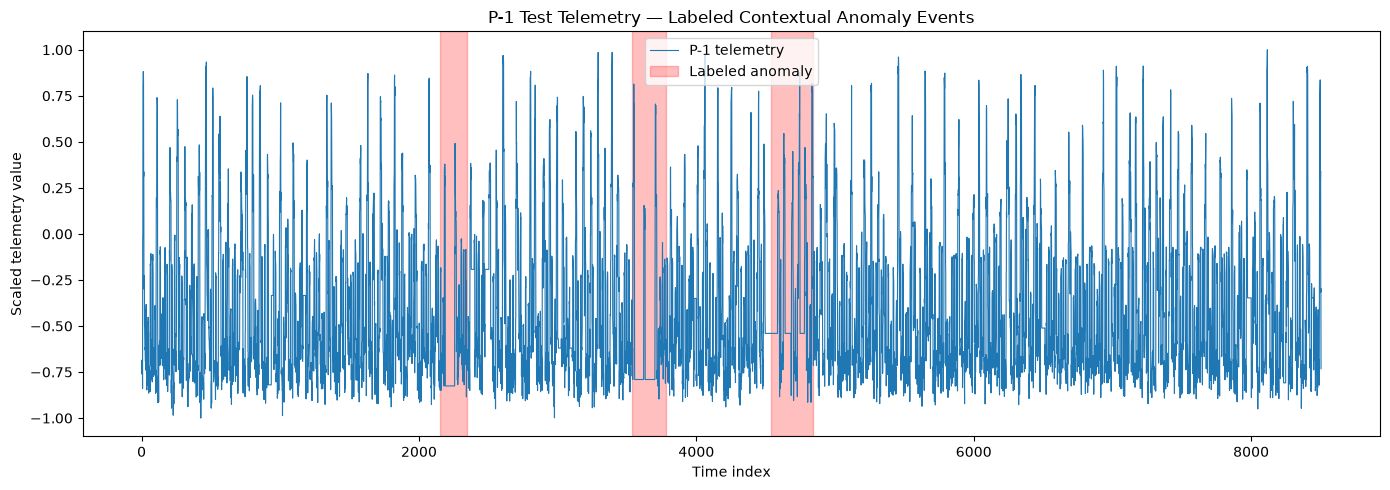

In [18]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    np.arange(len(p1_test)),
    p1_test,
    linewidth=0.8,
    label="P-1 telemetry"
)

for i, (start, end) in enumerate(p1_intervals):
    ax.axvspan(
        start,
        end,
        color = "red",
        alpha=0.25,
        label="Labeled anomaly" if i == 0 else None
    )

ax.set(
    title="P-1 Test Telemetry — Labeled Contextual Anomaly Events",
    xlabel="Time index",
    ylabel="Scaled telemetry value"
)

ax.legend()
plt.tight_layout()
plt.show()


# 4. Event-level evaluation

Each statistical method first produces a Boolean anomaly flag at every test time point.

For the project comparison, those consecutive flagged points are converted into **detected alert intervals**. For example, flags at indices 100, 101, and 102 form the detected interval $(100,102)$.

A labeled anomaly event $[a_j,b_j]$ is counted as detected when at least one detected alert overlaps that interval.

Equivalently, if $\hat A_t=1$ denotes a flagged time point, event $j$ is detected when

$$
\sum_{t=a_j}^{b_j} I(\hat A_t=1) > 0.
$$

The event-level counts are:

- **TP:** number of labeled anomaly events that overlap at least one detected alert,
- **FP:** number of detected alert intervals that overlap no labeled anomaly event,
- **FN:** number of labeled anomaly events that overlap no detected alert.

Event precision is

$$
\text{Event Precision}
=
\frac{TP}{TP+FP}.
$$

Event recall is

$$
\text{Event Recall}
=
\frac{TP}{TP+FN}.
$$

Since P-1 has three labeled events,

$$
\text{Event Recall}
=
\frac{\text{Number of labeled events detected}}{3}.
$$

The event-level F1 score is

$$
F1
=
2
\frac{
\text{Event Precision}\times\text{Event Recall}
}{
\text{Event Precision}+\text{Event Recall}
}.
$$

This event-level evaluation is closer to the final ARX, Random Forest, and LSTM comparisons than point-level classification metrics.


In [19]:
def flags_to_intervals(flags):
    """
    Convert a Boolean pointwise anomaly vector into contiguous
    inclusive (start, end) alert intervals.
    """
    positions = np.flatnonzero(flags)

    if len(positions) == 0:
        return []

    groups = np.split(
        positions,
        np.flatnonzero(
            np.diff(positions) > 1
        ) + 1
    )

    return [
        (int(group[0]), int(group[-1]))
        for group in groups
        if len(group) > 0
    ]


def intervals_overlap(interval_1, interval_2):
    """Return True when two inclusive intervals overlap."""
    start_1, end_1 = interval_1
    start_2, end_2 = interval_2

    return (
        start_1 <= end_2
        and start_2 <= end_1
    )


def evaluate_event_detection(
    detected_intervals,
    labeled_intervals
):
    """
    Evaluate detected alert intervals against labeled anomaly events.
    """
    detected_intervals = list(detected_intervals)
    labeled_intervals = list(labeled_intervals)

    detected_event_mask = np.array([
        any(
            intervals_overlap(
                labeled_interval,
                detected_interval
            )
            for detected_interval
            in detected_intervals
        )
        for labeled_interval
        in labeled_intervals
    ])

    false_alert_mask = np.array([
        not any(
            intervals_overlap(
                detected_interval,
                labeled_interval
            )
            for labeled_interval
            in labeled_intervals
        )
        for detected_interval
        in detected_intervals
    ])

    TP = int(detected_event_mask.sum())
    FP = int(false_alert_mask.sum())
    FN = int(
        len(labeled_intervals) - TP
    )

    precision = (
        TP / (TP + FP)
        if TP + FP > 0
        else np.nan
    )

    recall = (
        TP / (TP + FN)
        if TP + FN > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if np.isfinite(precision)
        and np.isfinite(recall)
        and precision + recall > 0
        else np.nan
    )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "detected_event_mask":
            detected_event_mask,
        "false_alert_mask":
            false_alert_mask
    }


# 5. Statistical baseline methods

The five methods are intentionally simple and interpretable.

For the score-based methods, the anomaly threshold is determined from the **training data only**. In particular, the 99th percentile of the training anomaly scores is used as the cutoff.

The empirical-rank method instead flags the most extreme 0.5% in each tail of the training empirical distribution.

The rolling methods use a window of $w=50$ previous observations. This value is retained from the earlier statistical-baseline analysis and is not tuned using the P-1 test anomaly labels.


## Baseline 1: Global z-score

The global z-score compares each telemetry value with the overall training mean and standard deviation.

Let the training mean and standard deviation be

$$
\mu_{\text{train}}
=
\frac{1}{n}
\sum_{i=1}^{n} x_i
$$

and

$$
\sigma_{\text{train}}
=
\sqrt{
\frac{1}{n}
\sum_{i=1}^{n}
(x_i-\mu_{\text{train}})^2
}.
$$

For a telemetry value $x_t$, the absolute global z-score is

$$
z_t
=
\left|
\frac{
x_t-\mu_{\text{train}}
}{
\sigma_{\text{train}}
}
\right|.
$$

The training data are scored in the same way. The anomaly threshold is the 99th percentile of the training z-scores:

$$
\tau_z
=
Q_{0.99}
\left(
z_1^{\text{train}},
\ldots,
z_n^{\text{train}}
\right).
$$

A test observation is flagged when

$$
z_t > \tau_z.
$$

This method is simple and interpretable, but it treats the telemetry distribution as globally stable and does not use recent temporal behavior.


In [20]:
def global_z_predictions(
    train_signal,
    test_signal
):
    mean = train_signal.mean()
    std = train_signal.std()

    # A constant training signal has no usable z-score.
    if std < 1e-12:
        return np.zeros(
            len(test_signal),
            dtype=bool
        )

    # Score the training observations.
    train_scores = np.abs(
        (train_signal - mean) / std
    )

    # Training-based cutoff.
    threshold = np.percentile(
        train_scores,
        99
    )

    # Apply the same scoring rule to test telemetry.
    test_scores = np.abs(
        (test_signal - mean) / std
    )

    return test_scores > threshold


## Baseline 2: Two-sided empirical rank

The empirical-rank method is nonparametric. It compares each test value with the empirical distribution of the training telemetry rather than assuming a Normal distribution.

The empirical cumulative distribution function is

$$
\widehat F_{\text{train}}(x)
=
\frac{1}{n}
\sum_{i=1}^{n}
I(x_i \le x).
$$

For a test value $x_t$, its empirical percentile is estimated relative to the training observations. The implementation uses a mid-rank treatment for ties.

A test observation is flagged if it falls in either extreme tail:

$$
\widehat F_{\text{train}}(x_t)
\le 0.005
$$

or

$$
\widehat F_{\text{train}}(x_t)
\ge 0.995.
$$

Thus, the method flags values in approximately the lowest 0.5% or highest 0.5% of the training empirical distribution.

Like the global z-score, this is a global method and does not explicitly use recent temporal behavior.


In [21]:
def rank_predictions(
    train_signal,
    test_signal
):
    sorted_train = np.sort(
        train_signal
    )

    n_train = len(
        sorted_train
    )

    left = np.searchsorted(
        sorted_train,
        test_signal,
        side="left"
    )

    right = np.searchsorted(
        sorted_train,
        test_signal,
        side="right"
    )

    # Mid-rank percentile for tied values.
    percentile = (
        (left + right) / 2
    ) / n_train

    # Flag the extreme 0.5% in either tail.
    return (
        (percentile <= 0.005)
        | (percentile >= 0.995)
    )


## Baseline 3: Rolling z-score

The rolling z-score allows the local mean and variability of the telemetry to change over time.

For a rolling window of size $w=50$, define the local mean from the **previous** $w$ observations as

$$
\bar x_{t,w}
=
\frac{1}{w}
\sum_{i=t-w}^{t-1} x_i.
$$

The corresponding local standard deviation is

$$
s_{t,w}
=
\sqrt{
\frac{1}{w}
\sum_{i=t-w}^{t-1}
(x_i-\bar x_{t,w})^2
}.
$$

The rolling z-score is

$$
z_t^{(\text{roll})}
=
\left|
\frac{
x_t-\bar x_{t,w}
}{
s_{t,w}
}
\right|.
$$

The current observation $x_t$ is not included in the window used to define its own local baseline.

The 99th percentile of the valid **training rolling z-scores** is used as the anomaly threshold:

$$
\tau_{\text{roll-z}}
=
Q_{0.99}
\left(
z_t^{(\text{roll, train})}
\right).
$$

A test observation is flagged when

$$
z_t^{(\text{roll})}
>
\tau_{\text{roll-z}}.
$$

A small standard-deviation floor is used in the code for numerical stability when a rolling window has almost no variation.


In [36]:
def rolling_z_predictions(
    train_signal,
    test_signal,
    window=50
):
    global_std = train_signal.std()

    # Numerical-stability floor.
    min_std = max(
        0.01 * global_std,
        1e-8
    )

    # -------------------------
    # Training rolling scores
    # -------------------------
    train_series = pd.Series(
        train_signal
    )

    train_mean = (
        train_series
        .shift(1)
        .rolling(window)
        .mean()
    )

    train_std = (
        train_series
        .shift(1)
        .rolling(window)
        .std(ddof=0)
        .clip(lower=min_std)
    )

    train_scores = np.abs(
        (train_series - train_mean)
        / train_std
    )

    valid_train_scores = train_scores[
        np.isfinite(train_scores)
    ]

    if len(valid_train_scores) == 0:
        return np.zeros(
            len(test_signal),
            dtype=bool
        )

    threshold = np.percentile(
        valid_train_scores,
        99
    )

    # ----------------------
    # Test rolling scores
    # ----------------------
    test_series = pd.Series(
        test_signal
    )

    test_mean = (
        test_series
        .shift(1)
        .rolling(window)
        .mean()
    )

    test_std = (
        test_series
        .shift(1)
        .rolling(window)
        .std(ddof=0)
        .clip(lower=min_std)
    )

    test_scores = np.abs(
        (test_series - test_mean)
        / test_std
    )

    return (
        (test_scores > threshold)
        .fillna(False)
        .to_numpy()
    )


## Baseline 4: Global robust z-score using the median and MAD

The usual z-score can be sensitive to skewness and extreme observations because both the mean and standard deviation are affected by outliers.

A robust alternative replaces the mean with the median and the standard deviation with the median absolute deviation.

Let

$$
m_{\text{train}}
=
\operatorname{median}
(x_1,\ldots,x_n)
$$

and define the training MAD as

$$
MAD_{\text{train}}
=
\operatorname{median}
\left(
|x_i-m_{\text{train}}|
\right).
$$

The robust z-score used here is

$$
r_t
=
\left|
0.6745
\frac{
x_t-m_{\text{train}}
}{
MAD_{\text{train}}
}
\right|.
$$

The constant $0.6745$ makes the MAD-based score comparable in scale to the usual z-score under a Normal distribution.

The anomaly threshold is the 99th percentile of the robust scores calculated on the training data:

$$
\tau_{\text{robust}}
=
Q_{0.99}
\left(
r_1^{\text{train}},
\ldots,
r_n^{\text{train}}
\right).
$$

A test observation is flagged when

$$
r_t > \tau_{\text{robust}}.
$$

This method is robust to extreme values but remains a global method: it does not adapt to changes in the recent local behavior of the telemetry.


In [37]:
def robust_z_predictions(
    train_signal,
    test_signal
):
    train_median = np.median(
        train_signal
    )

    train_mad = np.median(
        np.abs(
            train_signal
            - train_median
        )
    )

    if train_mad < 1e-12:
        return np.zeros(
            len(test_signal),
            dtype=bool
        )

    train_scores = np.abs(
        0.6745
        * (train_signal - train_median)
        / train_mad
    )

    threshold = np.percentile(
        train_scores,
        99
    )

    test_scores = np.abs(
        0.6745
        * (test_signal - train_median)
        / train_mad
    )

    return test_scores > threshold


## Baseline 5: Rolling median/MAD

The rolling median/MAD method combines **local adaptation** with **robust measures of center and spread**.

For a rolling window of the previous $w=50$ observations, define

$$
m_{t,w}
=
\operatorname{median}
(x_{t-w},\ldots,x_{t-1})
$$

and

$$
MAD_{t,w}
=
\operatorname{median}
\left(
|x_i-m_{t,w}|
:
i=t-w,\ldots,t-1
\right).
$$

The rolling robust anomaly score is

$$
r_t^{(\text{roll})}
=
\left|
0.6745
\frac{
x_t-m_{t,w}
}{
MAD_{t,w}
}
\right|.
$$

As with the rolling z-score, the current observation is excluded from the window used to define its own local reference distribution.

The anomaly threshold is the 99th percentile of the valid rolling median/MAD scores from the training data:

$$
\tau_{\text{roll-MAD}}
=
Q_{0.99}
\left(
r_t^{(\text{roll, train})}
\right).
$$

A test observation is flagged when

$$
r_t^{(\text{roll})}
>
\tau_{\text{roll-MAD}}.
$$

A small MAD floor is used for numerical stability when the local MAD is extremely small.

This method is designed to detect observations that are unusual relative to **recent local behavior** while reducing sensitivity to extreme values within the rolling window.


In [38]:
def rolling_mad_predictions(
    train_signal,
    test_signal,
    window=50
):
    # -------------------------
    # Training rolling scores
    # -------------------------
    train_series = pd.Series(
        train_signal
    )

    train_median = (
        train_series
        .shift(1)
        .rolling(window)
        .median()
    )

    train_mad = (
        train_series
        .shift(1)
        .rolling(window)
        .apply(
            lambda x: np.median(
                np.abs(
                    x - np.median(x)
                )
            ),
            raw=True
        )
    )

    # Use the global training MAD only to create
    # a small numerical-stability floor.
    global_median = np.median(
        train_signal
    )

    global_mad = np.median(
        np.abs(
            train_signal
            - global_median
        )
    )

    min_mad = max(
        0.01 * global_mad,
        1e-8
    )

    train_mad_safe = train_mad.clip(
        lower=min_mad
    )

    train_scores = np.abs(
        0.6745
        * (train_series - train_median)
        / train_mad_safe
    )

    valid_train_scores = train_scores[
        np.isfinite(train_scores)
    ]

    if len(valid_train_scores) == 0:
        return np.zeros(
            len(test_signal),
            dtype=bool
        )

    threshold = np.percentile(
        valid_train_scores,
        99
    )

    # ----------------------
    # Test rolling scores
    # ----------------------
    test_series = pd.Series(
        test_signal
    )

    test_median = (
        test_series
        .shift(1)
        .rolling(window)
        .median()
    )

    test_mad = (
        test_series
        .shift(1)
        .rolling(window)
        .apply(
            lambda x: np.median(
                np.abs(
                    x - np.median(x)
                )
            ),
            raw=True
        )
    )

    test_mad_safe = test_mad.clip(
        lower=min_mad
    )

    test_scores = np.abs(
        0.6745
        * (test_series - test_median)
        / test_mad_safe
    )

    return (
        (test_scores > threshold)
        .fillna(False)
        .to_numpy()
    )


# 6. Apply all five statistical baselines

Each method produces pointwise anomaly flags internally. Those flags are then grouped into contiguous alert intervals for the final event-level evaluation.

The summary table reports only event-level quantities:

- number of detected alert intervals,
- $TP$ labeled events,
- $FP$ alert intervals,
- $FN$ labeled events,
- event precision,
- event recall,
- event F1.


In [39]:
methods = {
    "Global z-score":
        global_z_predictions,

    "Global robust z-score":
        robust_z_predictions,

    "Two-sided empirical rank":
        rank_predictions,

    "Rolling z-score (w=50)":
        lambda tr, te:
        rolling_z_predictions(
            tr,
            te,
            window=50
        ),

    "Rolling median/MAD (w=50)":
        lambda tr, te:
        rolling_mad_predictions(
            tr,
            te,
            window=50
        ),
}

point_flags = {}
detected_intervals_by_method = {}

summary_rows = []
event_rows = []

for method_name, method_fn in methods.items():
    # Statistical method generates pointwise flags.
    flags = method_fn(
        p1_train,
        p1_test
    )

    point_flags[method_name] = flags

    # Convert consecutive flags to event-level alert intervals.
    detected_intervals = flags_to_intervals(
        flags
    )

    detected_intervals_by_method[
        method_name
    ] = detected_intervals

    evaluation = evaluate_event_detection(
        detected_intervals,
        p1_intervals
    )

    summary_rows.append({
        "method": method_name,
        "detected_alerts":
            len(detected_intervals),
        "TP": evaluation["TP"],
        "FP": evaluation["FP"],
        "FN": evaluation["FN"],
        "event_precision":
            evaluation["precision"],
        "event_recall":
            evaluation["recall"],
        "event_f1":
            evaluation["f1"],
    })

    for event_number, (
        interval,
        detected
    ) in enumerate(
        zip(
            p1_intervals,
            evaluation[
                "detected_event_mask"
            ]
        ),
        start=1
    ):
        event_rows.append({
            "method": method_name,
            "event": event_number,
            "labeled_interval":
                f"{interval[0]}-{interval[1]}",
            "detected":
                bool(detected),
        })

summary = pd.DataFrame(
    summary_rows
)

event_detail = pd.DataFrame(
    event_rows
)

display(
    summary.round(4)
)


,method,detected_alerts,TP,FP,FN,event_precision,event_recall,event_f1
0,Global z-score,40,2,37,1,0.0513,0.6667,0.0952
1,Global robust z-score,40,2,37,1,0.0513,0.6667,0.0952
2,Two-sided empirical rank,46,2,43,1,0.0444,0.6667,0.0833
3,Rolling z-score (w=50),54,3,47,0,0.0600,1.0000,0.1132
4,Rolling median/MAD (w=50),18,3,4,0,0.4286,1.0000,0.6000


## 7. Event-by-event detection

The table below shows whether each statistical baseline detected each of the three labeled P-1 anomaly events.

No point-level recall is reported because the main project question is whether the anomaly **event** was detected.


In [40]:
event_table = (
    event_detail
    .pivot(
        index="method",
        columns="event",
        values="detected"
    )
    .rename(
        columns={
            1: "Event 1: 2149-2349",
            2: "Event 2: 3539-3779",
            3: "Event 3: 4536-4844",
        }
    )
)

display(
    event_table
)


event,Event 1: 2149-2349,Event 2: 3539-3779,Event 3: 4536-4844
method,,,
Global robust z-score,False,True,True
Global z-score,False,True,True
Rolling median/MAD (w=50),True,True,True
Rolling z-score (w=50),True,True,True
Two-sided empirical rank,False,True,True


## 8. Event-level performance comparison

Event recall measures how many of the three labeled P-1 anomaly events were detected.

Event precision penalizes methods that produce detected alert intervals outside the labeled anomaly events.

Therefore, a method that detects all three anomalies but also produces many unrelated alerts will not receive perfect event-level performance.


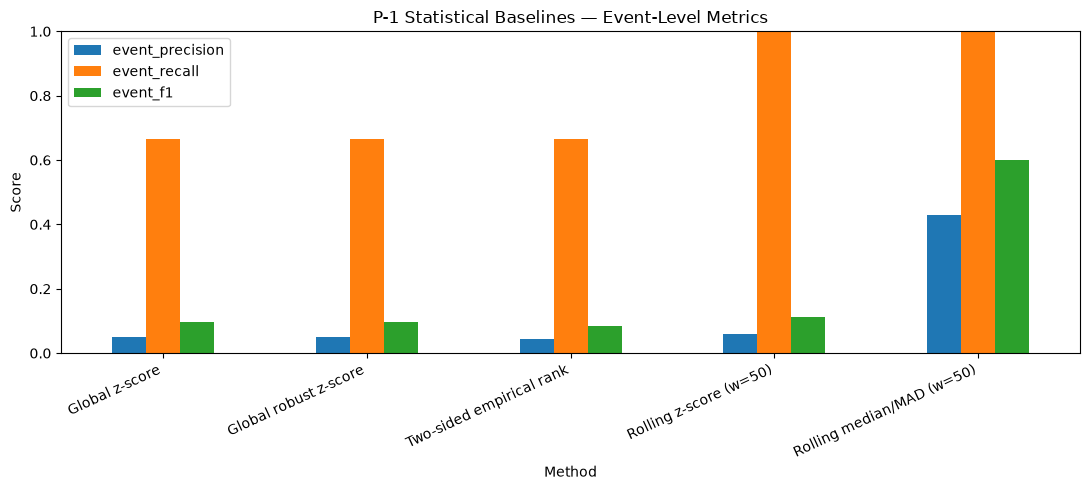

In [41]:
metric_plot = (
    summary[
        [
            "method",
            "event_precision",
            "event_recall",
            "event_f1"
        ]
    ]
    .set_index("method")
)

ax = metric_plot.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set(
    title="P-1 Statistical Baselines — Event-Level Metrics",
    xlabel="Method",
    ylabel="Score"
)

ax.set_ylim(0, 1)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()
plt.show()


## 9. Visualize labeled events and detected alert intervals

The plots below show:

- the P-1 telemetry,
- the three labeled anomaly intervals,
- the contiguous alert intervals generated by each statistical baseline.

This visualization is more aligned with the project goal than displaying individual pointwise flags.


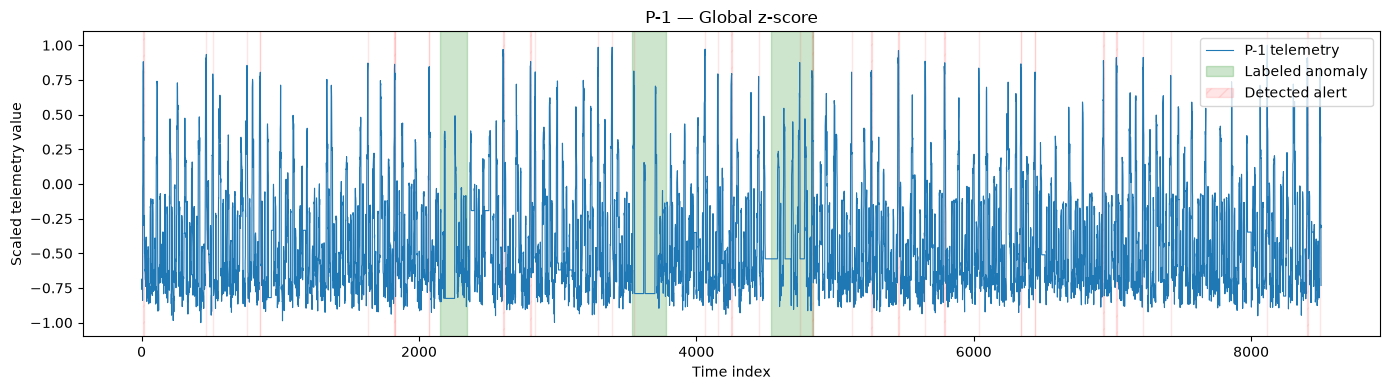

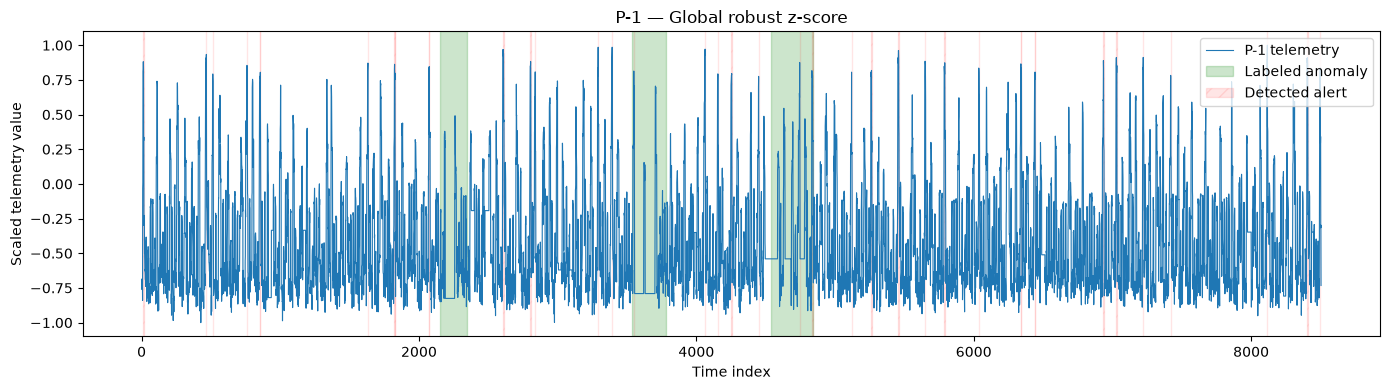

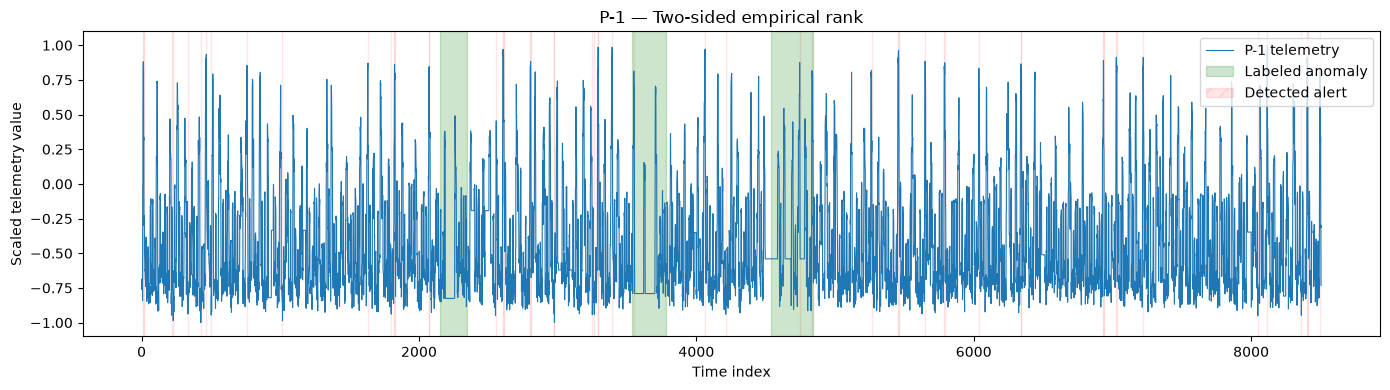

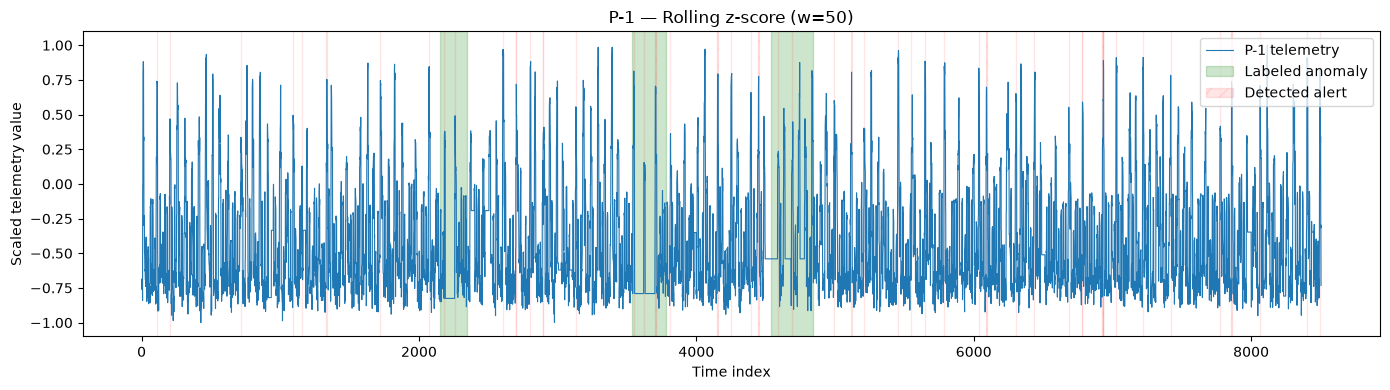

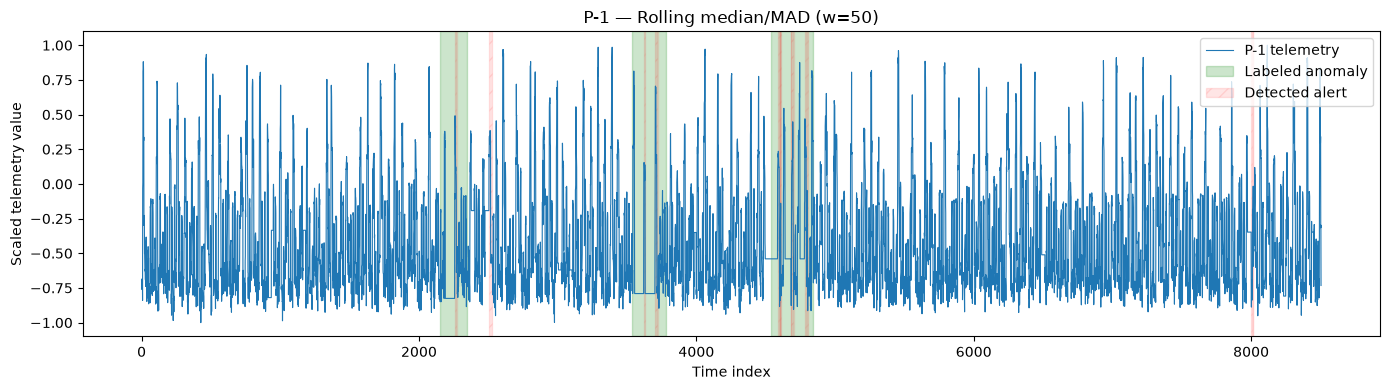

In [42]:
for method_name, detected_intervals in (
    detected_intervals_by_method.items()
):
    fig, ax = plt.subplots(
        figsize=(14, 4)
    )

    indices = np.arange(
        len(p1_test)
    )

    ax.plot(
        indices,
        p1_test,
        linewidth=0.8,
        label="P-1 telemetry"
    )

    # Ground-truth anomaly intervals.
    for i, (start, end) in enumerate(
        p1_intervals
    ):
        ax.axvspan(
            start,
            end,
            color = "green",
            alpha=0.20,
            label=(
                "Labeled anomaly"
                if i == 0
                else None
            )
        )

    # Statistical baseline alert intervals.
    for i, (start, end) in enumerate(
        detected_intervals
    ):
        ax.axvspan(
            start,
            end,
            color = "red",
            alpha=0.10,
            hatch="//",
            label=(
                "Detected alert"
                if i == 0
                else None
            )
        )

    ax.set(
        title=f"P-1 — {method_name}",
        xlabel="Time index",
        ylabel="Scaled telemetry value"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()


# 10. Interpretation

The global z-score, empirical-rank, and global robust z-score methods judge observations mainly by how extreme they are relative to the overall training distribution.

That can be limiting for P-1 because its labeled anomalies are contextual rather than simple isolated extremes.

The rolling methods instead ask whether the current telemetry is unusual relative to its **recent local behavior**.

In the P-1 results already observed in the earlier notebook:

- the global z-score detected 2 of the 3 labeled events,
- the global robust z-score detected 2 of 3,
- the empirical-rank method detected 2 of 3,
- the rolling z-score detected all 3,
- the rolling median/MAD method detected all 3.

The revised event-level evaluation additionally counts how many separate false alert intervals each method produces. This is important because detecting all three true events is less useful if a method also generates many unrelated alerts.

The statistical baselines use **telemetry only**. They do not use the 24 context/command variables and they do not use the Telemanom post-prediction detector.

They should therefore be treated as simple reference baselines rather than direct architectural equivalents of ARX, Random Forest, or LSTM forecasting followed by Telemanom detection.


# 11. Limitations

- Only the P-1 telemetry column is used.
- The 24 context/command variables are not used by these statistical baselines.
- The rolling window size is fixed at $w=50$ from the earlier exploratory baseline analysis.
- The score-based cutoffs use the 99th percentile of training scores and are not tuned using the P-1 test labels.
- The empirical-rank method uses fixed 0.5% lower and upper tails.
- Pointwise flags are grouped into contiguous alert intervals without adding an extra buffer or merging separated alerts.
- These baselines do not use Telemanom's error smoothing, dynamic thresholding, buffering, or pruning.
